In [10]:
import numpy as np
import pandas as pd
import pickle
import glob
import os

import matplotlib.pyplot as plt
import matplotlib as mpl
%matplotlib inline

from scipy.stats import gaussian_kde

mpl.rcParams['font.size'] = 8.0
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [11]:
Fs          = 3e4                    # sampling window used every
TimeHistory = 20e-3                  # 20 ms STA window
L           = int(TimeHistory * Fs)  # 600 samples — STA length for projection

DATA_BASE = './dataFolder/'           # Prediction's own outputs (train models live here)
ORIG_BASE = '../dataFolder/'          # original pipeline (test data lives here)

model_path = DATA_BASE + '5_1DCompModel_Train/'
test_path  = ORIG_BASE + '4_RawData_Index_Timestamp/Test/'
out_fig    = DATA_BASE + 'Figures_Prediction/'
out_data   = DATA_BASE + '5_1DCompModel_Train/Prediction/'

os.makedirs(out_fig,  exist_ok=True)
os.makedirs(out_data, exist_ok=True)

In [12]:
moth_to_full = {
    'm23': 'm23_wn2',
    'm29': 'm29_wn2',
    'm30': 'm30_wn1',
    'm31': 'm31_wn2',
    'm11': 'm11_wn2',
}

In [13]:
def predictFiringRate(stimulus, sta, nld_func, prior_std, bin_fwdModel):
    sta_length            = len(sta) #600 samples- 20ms of STA History 
    total_stimulus_length = len(stimulus) #3e4 of test sample (in this case same stim)
    
    proj = np.full(shape=total_stimulus_length, fill_value=np.nan) #(first 600 samples will stay NaN — no history yet)
    for i in np.arange(sta_length, total_stimulus_length):
        segment = stimulus[i - sta_length:i] # the 20 ms window just before sample i
        proj[i] = np.dot(sta, segment) / prior_std # z-scored similarity between that part of stim & STA
        if proj[i] < np.min(bin_fwdModel):
            proj[i] = np.min(bin_fwdModel)
        elif proj[i] > np.max(bin_fwdModel):
            proj[i] = np.max(bin_fwdModel)
    
    chunk_size   = int(0.007 * Fs)   # 0.007 s × 30,000 Hz = 210 samples per chunk
    proj_trimmed = proj[sta_length:] # drop 600 NaN entries-proj_trimmed has length ~299,400 samples
    n_bins       = len(proj_trimmed) // chunk_size # how many full 7 ms chunks fit: ~1,426, exclude those that don't fit exactly
    proj_chunked = proj_trimmed[:n_bins * chunk_size].reshape(n_bins, chunk_size) 
    # proj_chunked is now a 2D array: 1,426 rows × 210 columns
    # each row = one 7 ms window of projection samples
    bin_max      = proj_chunked.max(axis=1) # per-chunk max projection (1426 values)
    
    pred_max     = nld_func(bin_max) # per-chunk NLD output (1426 values)- (n_ste / n_prior, from train NLD
    
    df_proj = pd.DataFrame({
        'bin_max':  bin_max,  
        'pred_max': pred_max})
    
    return df_proj, proj_trimmed                     # also return per-sample projection

Found 8 train clipped models

processing m11 unit_2
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


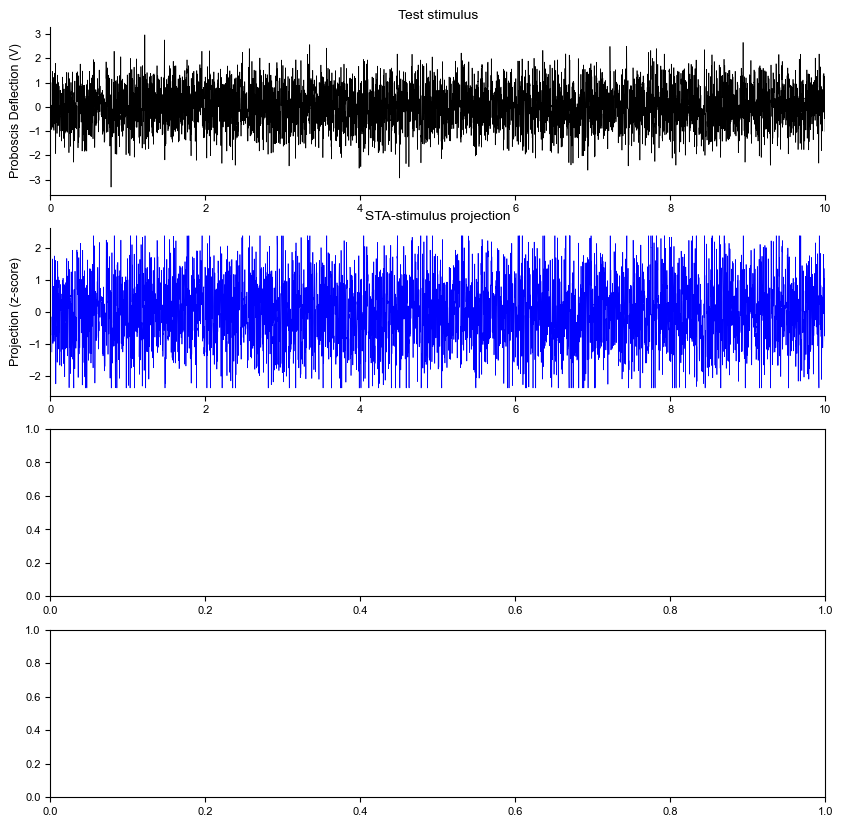

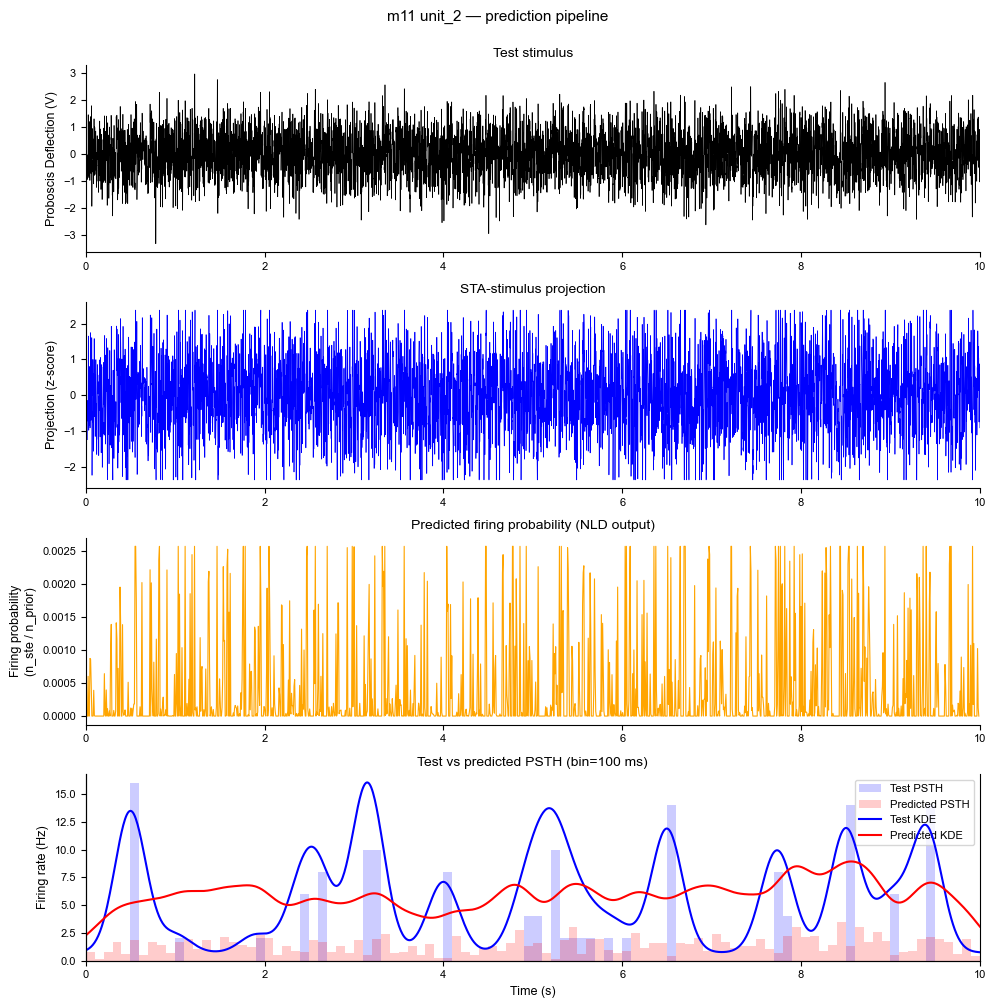

  test_psth mean: 1.52 Hz, pred_psth mean: 1.41 Hz

processing m11 unit_3
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


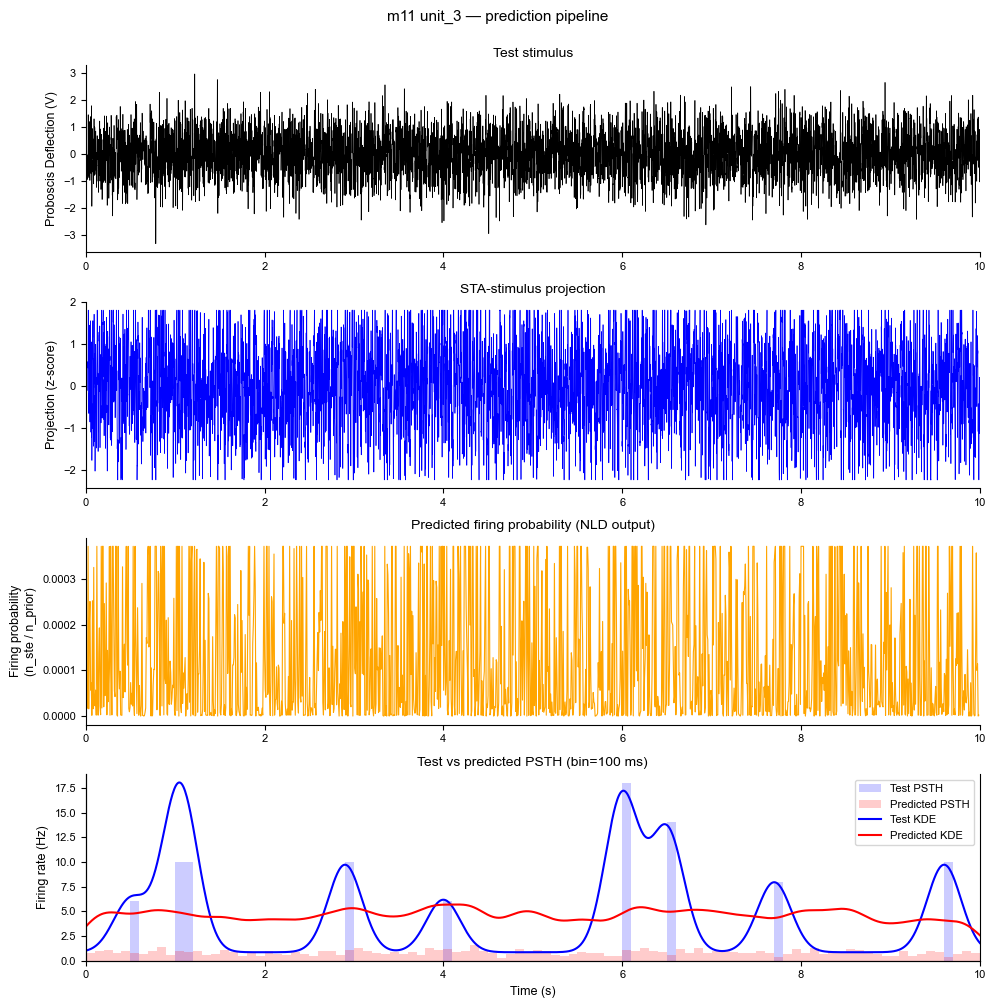

  test_psth mean: 0.92 Hz, pred_psth mean: 0.84 Hz

processing m23 unit_1
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


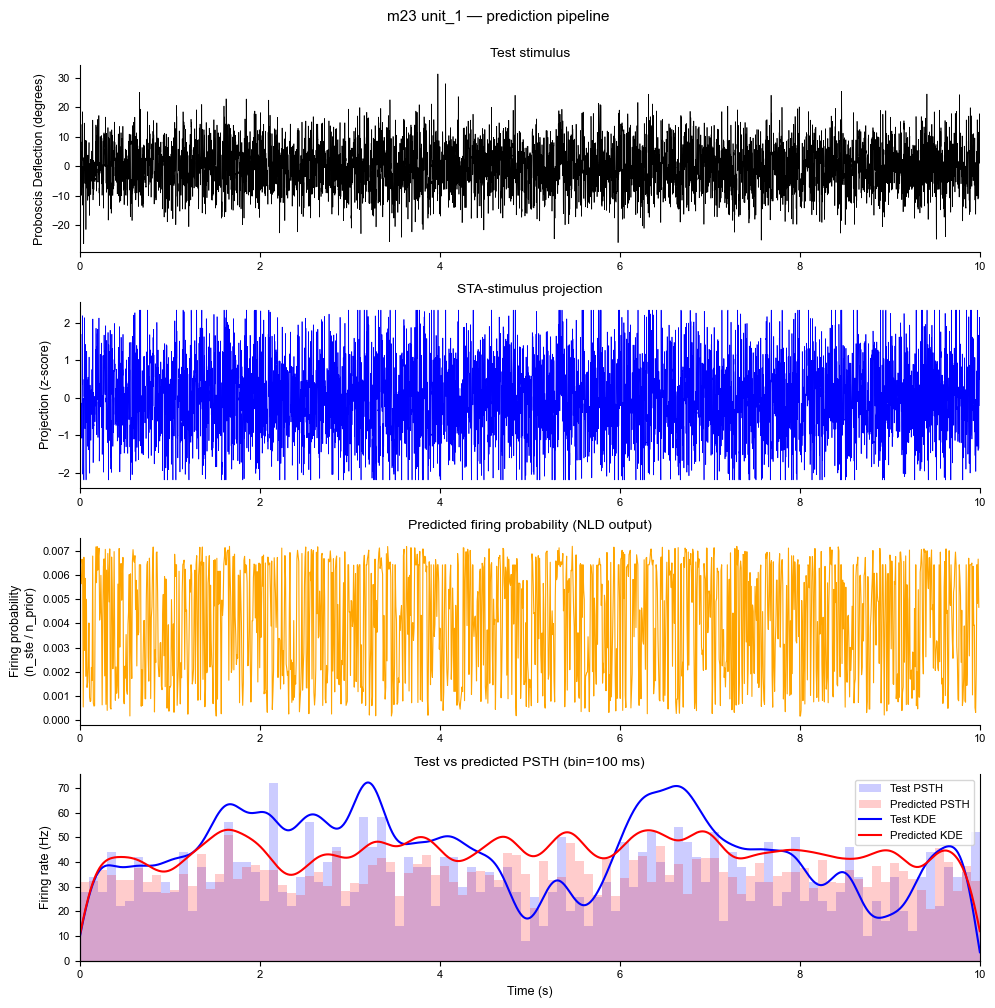

  test_psth mean: 33.68 Hz, pred_psth mean: 35.04 Hz

processing m29 unit_1
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


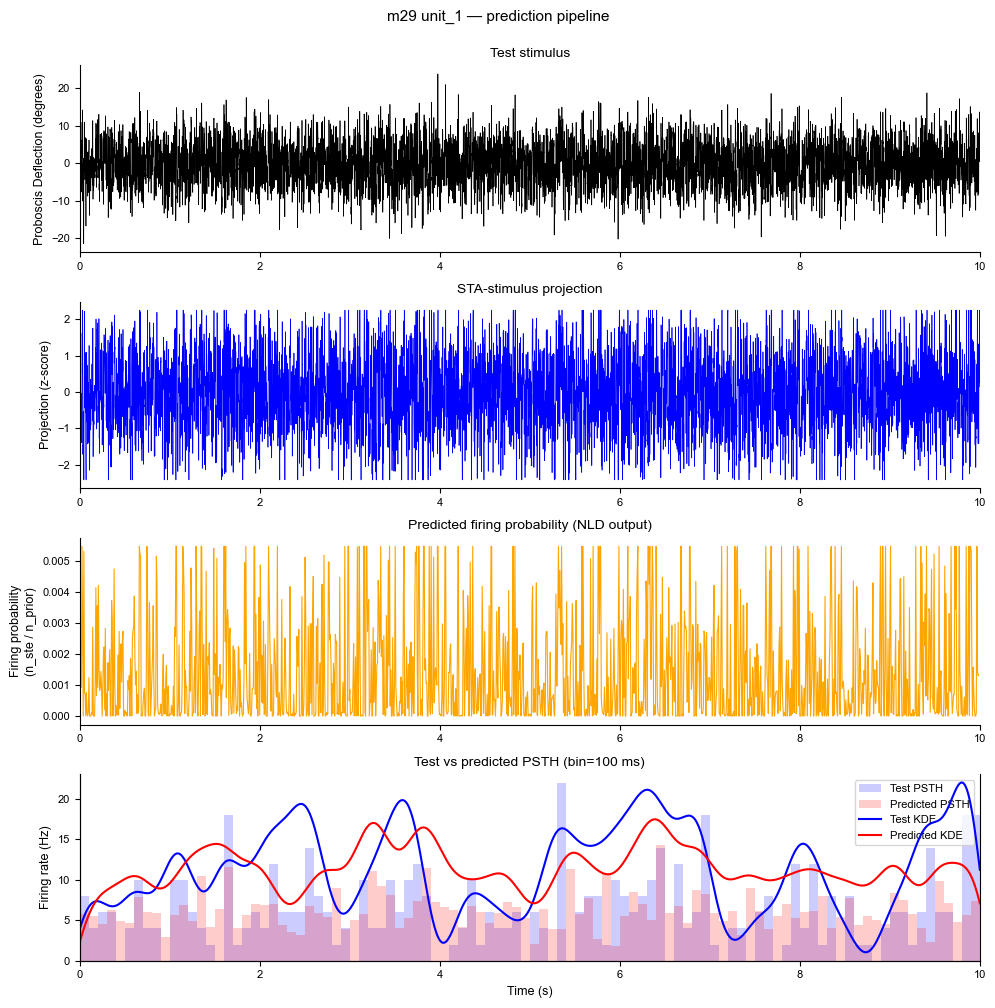

  test_psth mean: 5.92 Hz, pred_psth mean: 6.24 Hz

processing m30 unit_1
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


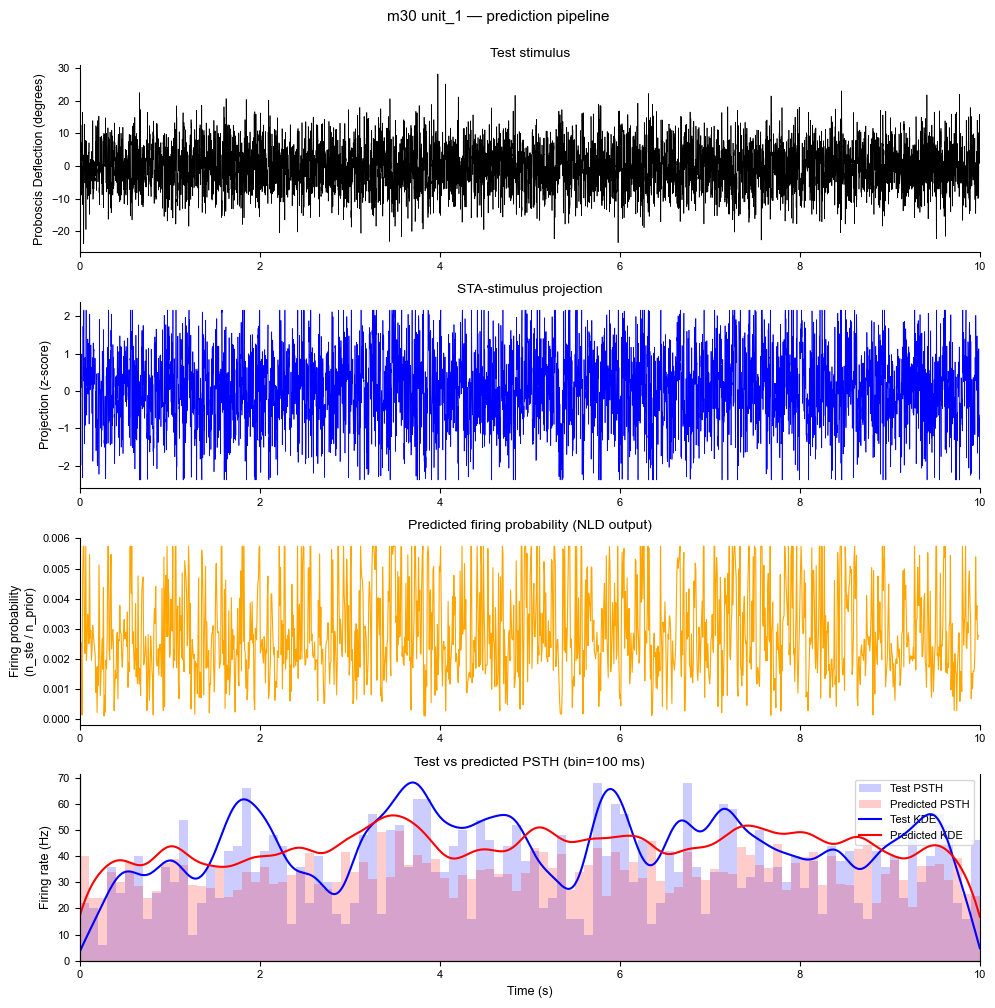

  test_psth mean: 35.94 Hz, pred_psth mean: 34.05 Hz

processing m31 unit_1
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


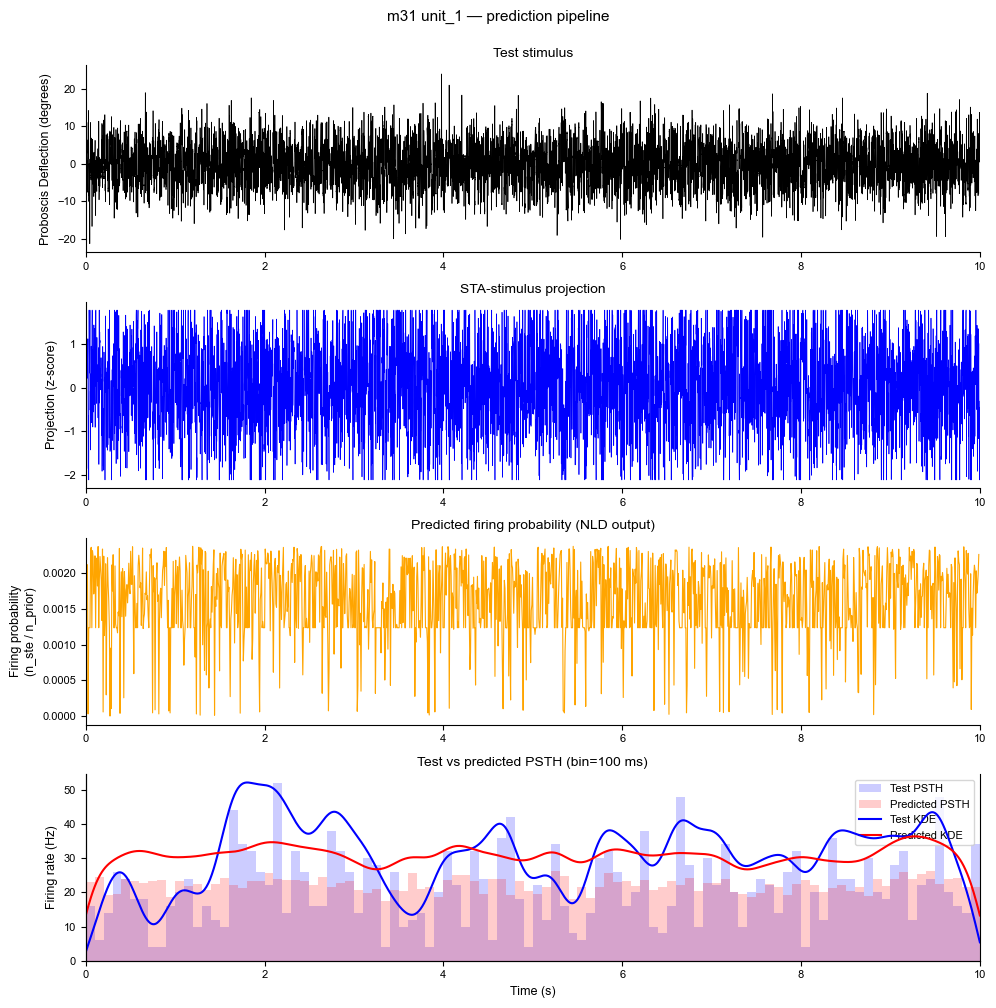

  test_psth mean: 21.42 Hz, pred_psth mean: 22.28 Hz

processing m31 unit_2
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


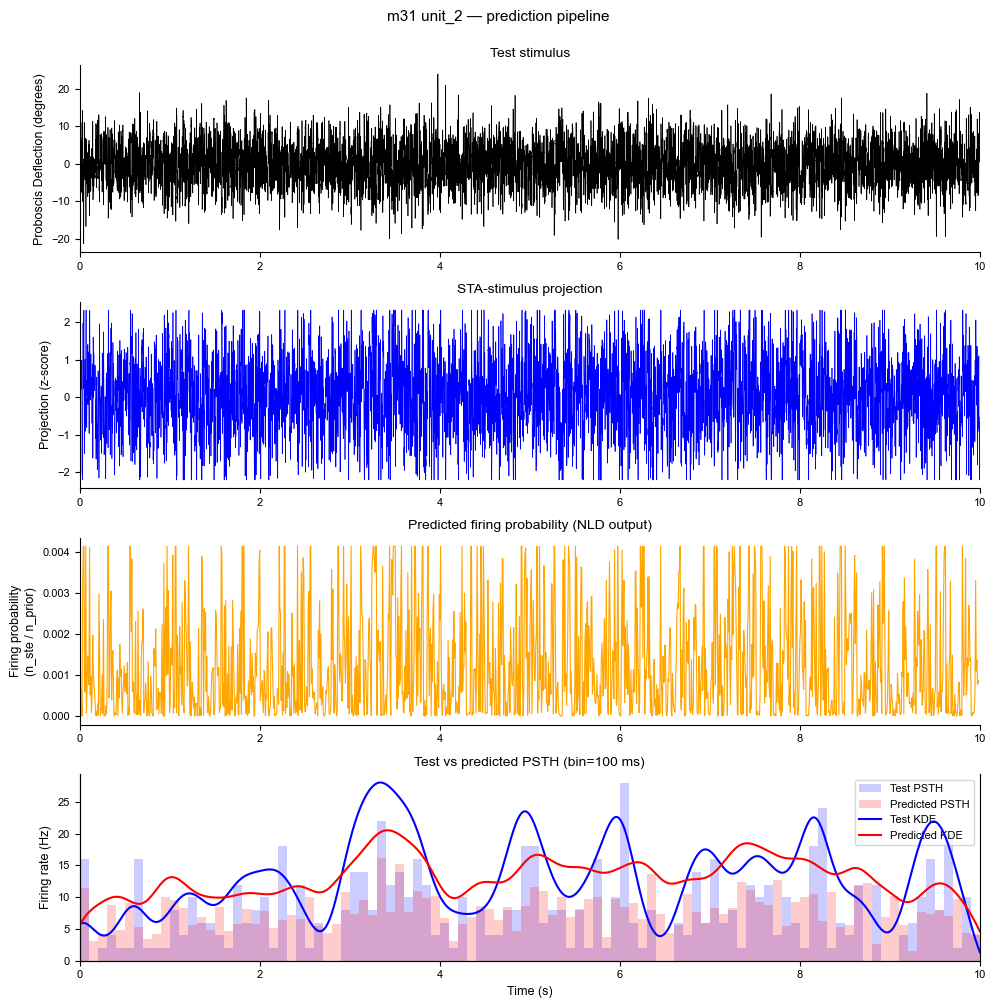

  test_psth mean: 7.66 Hz, pred_psth mean: 7.80 Hz

processing m31 unit_3
  n_pred_bins: 101 (each bin = 14 chunks = 100 ms)


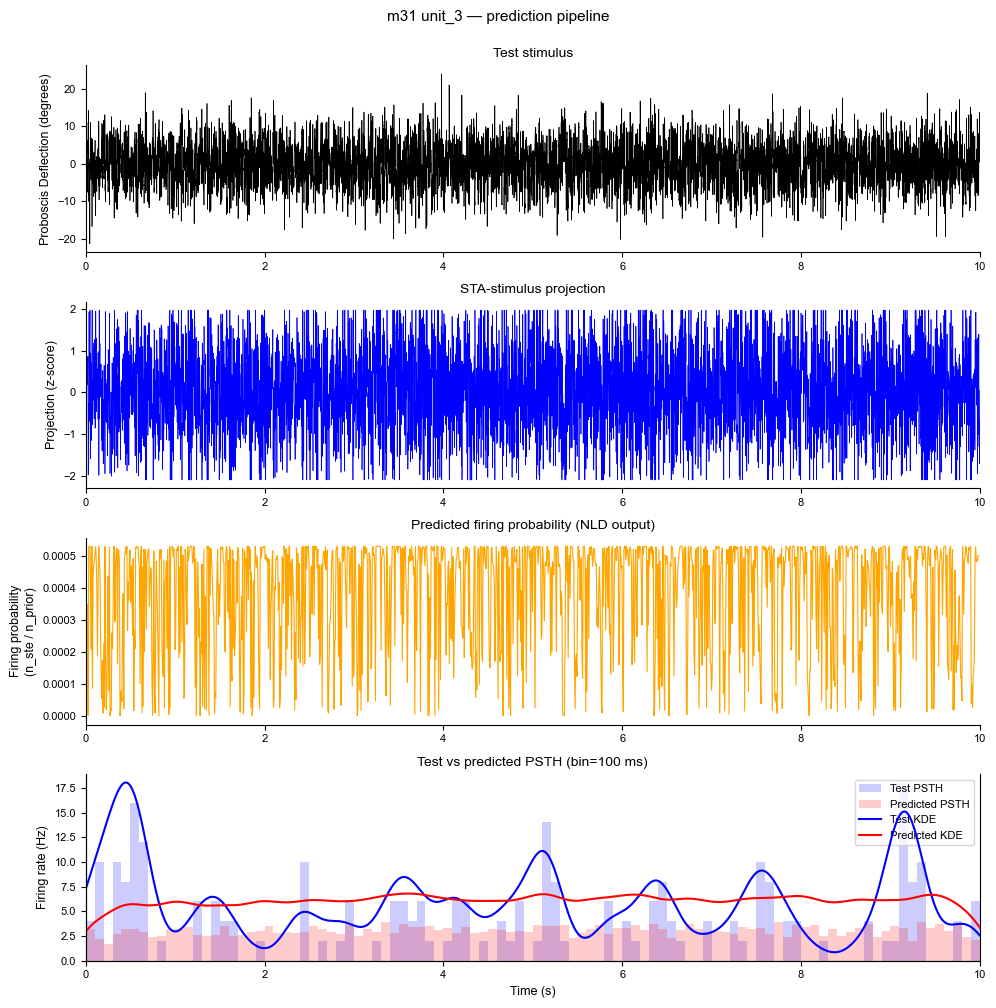

  test_psth mean: 3.08 Hz, pred_psth mean: 3.08 Hz


In [18]:
model_files = sorted(glob.glob(model_path + '*_TrainClippedModel.pickle'))
print(f'Found {len(model_files)} train clipped models')

bin_size      = 0.1 #can change- also used chunk size 
stim_duration = 10.0 #one repeat of the stim in s

for filepath in model_files:
    base   = os.path.basename(filepath)
    name   = base.split('_')[0]
    unitID = '_'.join(base.split('_')[1:3])
    print(f'\nprocessing {name} {unitID}')
    
    # load train model
    with open(filepath, 'rb') as f:
        savedModel = pickle.load(f)
    sta          = savedModel[1].values # STA from train, 660 samples(incl. 2 ms post but not needed here)
    prior_std    = savedModel[6]  #std of train projected_prior 
    bin_fwdModel = savedModel[12] # clipped NLD x-axis (z-score bin centers)
    nld_fwdModel = savedModel[13] # clipped NLD y-axis (firing probability per bin)
    
    nld_func = lambda x, _b=bin_fwdModel, _n=nld_fwdModel: np.interp(x, _b, _n) #interpolation - lambda loops the NLD lookup for all the units
    sta = sta[:L] #remove the post spike from STA
    
    # load test pickle (degrees if available, else scaled for m11)
    moth_full = moth_to_full[name]
    test_file_degrees = test_path + moth_full + '_timeStamps_degrees.pickle'
    test_file_scaled  = test_path + moth_full + '_timeStamps_scaled.pickle'
    if os.path.exists(test_file_degrees):
        test_file = test_file_degrees
    elif os.path.exists(test_file_scaled):
        test_file = test_file_scaled
    else:
        print(f'  no test file for {moth_full}, skipping')
        continue
    with open(test_file, 'rb') as f:
        test_out = pickle.load(f)
    all_Units_aligned = test_out[0]
    WhiteNoise        = test_out[2].values
    
    # predict firing rate (returns chunk-resolution df + per-sample projection)
    df_proj, proj_per_sample = predictFiringRate(WhiteNoise, sta, nld_func, prior_std, bin_fwdModel)
    
    # pred_max is always at 7ms chunk resolution- NLD will also have only same lookup as max of chunked points 
    chunk_size_s    = 0.007                              
    pred_chunk      = df_proj['pred_max'].values         # 1426 values at 7 ms
    chunks_per_bin  = int(round(bin_size / chunk_size_s)) # how many 7 ms chunks make one PSTH bin, bin_size=0.007 means one chunk in a bin
    n_pred_bins     = len(pred_chunk) // chunks_per_bin # total PSTH bins after rebinning
    pred_psth       = pred_chunk[:n_pred_bins * chunks_per_bin].reshape(n_pred_bins, chunks_per_bin).mean(axis=1)
    print(f'  n_pred_bins: {n_pred_bins} (each bin = {chunks_per_bin} chunks = {bin_size*1000:.0f} ms)')
    
    # rescale predicted PSTH from NLD units to firing rate 
    n_train_spikes = len(savedModel[0]) # rows of train STE = total train spikes
    train_duration = 25 * 10.0 # 25 train repeats × 10 s = 250 s
    baseline_rate  = n_train_spikes / train_duration # train mean firing- 8758 spikes/250= 35.03
    nld_mean       = np.mean(pred_psth[pred_psth > 0]) #if pred_psth [0.1,0.4 etc] then mean of this. non-zero filter to not artificially bring it down
    pred_psth      = (pred_psth / nld_mean) * baseline_rate 
    pred_edges     = np.arange(n_pred_bins) * bin_size
    
    # KDE on predicted PSTH
    kde_pred     = gaussian_kde(pred_edges, weights=pred_psth, bw_method=0.06)
    x_grid       = np.linspace(0, stim_duration, 1000)
    density_pred = kde_pred(x_grid)
    
    # actual test PSTH from spikes
    spikes      = np.concatenate(all_Units_aligned[unitID])
    num_repeats = len(all_Units_aligned[unitID])
    edges       = np.arange(0, stim_duration + bin_size, bin_size)
    counts, _   = np.histogram(spikes, bins=edges)
    test_psth   = counts / (num_repeats * bin_size)
    
    # KDE on test PSTH
    kde_test     = gaussian_kde(edges[:-1], weights=test_psth, bw_method=0.06)
    density_test = kde_test(x_grid)
    
    # # save everything for downstream RMSE / box plot
    # saveObject = (bin_fwdModel, nld_fwdModel,
    #               df_proj, test_psth, edges[:-1],
    #               pred_psth, pred_edges,
    #               density_test, density_pred, x_grid)
    # with open(out_data + name + '_' + unitID + '_Prediction.pickle', 'wb') as f:
    #     pickle.dump(saveObject, f)
    
    # === 4-panel pipeline figure ===
    fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=False)
    t_axis = np.arange(len(WhiteNoise)) / Fs
    
    # Panel 1: stimulus (per-sample)
    axes[0].plot(t_axis, WhiteNoise, color='black', linewidth=0.5)
    if name == 'm11':
        axes[0].set_ylabel('Proboscis Deflection (V)', fontsize=9)
    else:
        axes[0].set_ylabel('Proboscis Deflection (degrees)', fontsize=9)
    axes[0].set_title('Test stimulus', fontsize=10)
    axes[0].set_xlim(0, 10)
    axes[0].spines['top'].set_visible(False)
    axes[0].spines['right'].set_visible(False)
    
    # Panel 2: STA-stimulus projection (per-sample, raw signal)
    proj_full = np.full(len(WhiteNoise), np.nan)
    proj_full[len(proj_full) - len(proj_per_sample):] = proj_per_sample
    axes[1].plot(t_axis, proj_full, color='blue', linewidth=0.5)
    axes[1].set_ylabel('Projection (z-score)', fontsize=9)
    axes[1].set_title('STA-stimulus projection', fontsize=10)
    axes[1].set_xlim(0, 10)
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['right'].set_visible(False)
    
    # Panel 3: predicted firing probability (NLD output) — chunk resolution
    chunk_size_samples = int(0.007 * Fs)
    n_chunks           = len(df_proj['pred_max'])        # always 1426 at chunk resolution
    t_pred             = (np.arange(n_chunks) * chunk_size_samples + (len(WhiteNoise) - len(proj_per_sample))) / Fs
    axes[2].plot(t_pred, df_proj['pred_max'].values, color='orange', linewidth=0.8)
    axes[2].set_ylabel('Firing probability\n(n_ste / n_prior)', fontsize=9)
    axes[2].set_title('Predicted firing probability (NLD output)', fontsize=10)
    axes[2].set_xlim(0, 10)
    axes[2].spines['top'].set_visible(False)
    axes[2].spines['right'].set_visible(False)
    
    # Panel 4: test vs predicted PSTH overlay (bars + KDE, twin axis)
    ax_psth = axes[3]
    ax_kde  = ax_psth.twinx()
    ax_psth.bar(edges[:-1], test_psth, width=bin_size, align='edge',
                color='blue', alpha=0.2, edgecolor='none', label='Test PSTH')
    ax_psth.bar(pred_edges, pred_psth, width=bin_size, align='edge',
                color='red', alpha=0.2, edgecolor='none', label='Predicted PSTH')
    ax_psth.set_ylabel('Firing rate (Hz)', fontsize=9)
    ax_psth.set_xlabel('Time (s)', fontsize=9)
    ax_kde.plot(x_grid, density_test, color='blue', linewidth=1.5, label='Test KDE')
    ax_kde.plot(x_grid, density_pred, color='red',  linewidth=1.5, label='Predicted KDE')
    ax_kde.set_yticks([])
    ax_kde.set_ylabel('')
    ax_psth.set_title(f'Test vs predicted PSTH (bin={int(bin_size*1000)} ms)', fontsize=10)
    ax_psth.set_xlim(0, 10)
    ax_psth.spines['top'].set_visible(False)
    ax_kde.spines['top'].set_visible(False)
    ax_kde.spines['right'].set_visible(False)
    h1, l1 = ax_psth.get_legend_handles_labels()
    h2, l2 = ax_kde.get_legend_handles_labels()
    ax_psth.legend(h1+h2, l1+l2, fontsize=8, loc='upper right')
    
    fig.suptitle(f'{name} {unitID} — prediction pipeline', fontsize=11, y=1.00)
    plt.tight_layout()
    
    # save
    out_path = './dataFolder/Figures_Summary/PredictionPipeline/'
    os.makedirs(out_path, exist_ok=True)
    fig.savefig(out_path + f'{name}_{unitID}_4panel_bin{int(bin_size*1000)}ms.pdf', 
                bbox_inches='tight')
    
    plt.show()
    print(f'  test_psth mean: {np.mean(test_psth):.2f} Hz, pred_psth mean: {np.mean(pred_psth):.2f} Hz')